In [10]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

src = Path("src")

# every run we want to compare: name -> folder
runs = {
    "MLP": src / "mlp/01-baseline",
    "CNN": src / "cnn/01-baseline",
    "U-Net 1": src / "unet/01-baseline",
    "U-Net 2": src / "unet/02-cosine-lr",
    "Faster R-CNN": src / "faster-rcnn/01-baseline",
    "DINOv3": src / "dinov3/01-baseline",
}

# load each run's history.json
histories = {}
for name, folder in runs.items():
    try:
        histories[name] = json.loads((folder / "history.json").read_text())
        print(f"Succesfully loaded: {name}")
    except Exception as e:
        print(f"There is an error regarding {name}: {r}")

Succesfully loaded: MLP
Succesfully loaded: CNN
Succesfully loaded: U-Net 1
Succesfully loaded: U-Net 2
Succesfully loaded: Faster R-CNN
Succesfully loaded: DINOv3


In [15]:
out_dir = src / "comparison"
out_dir.mkdir(exist_ok=True)   # create the folder if it doesn't exist

In [16]:
# Faster R-CNN predicts boxes, not masks, so it has no pixel IoU
seg_models = ["MLP", "CNN", "U-Net 1", "U-Net 2", "DINOv3"]

rows = []
for name in seg_models:
    h = histories[name]
    best = h["val_iou"].index(max(h["val_iou"]))   # epoch with the highest IoU
    rows.append({
        "Model": name,
        "Best epoch": best + 1,
        "Val IoU": round(h["val_iou"][best], 4),
        "Cutoff": h["best_cutoff"][best] if "best_cutoff" in h else 0.5,
    })

table = pd.DataFrame(rows).rename(columns={"Val IoU": "Val IoU (higher is better)"})

# save as csv (to open anywhere) and as LaTeX (to paste into the report)
table.to_csv(out_dir / "pixel_iou.csv", index=False)
table.to_latex(out_dir / "pixel_iou.tex", index=False)

# green background on the best IoU
table.style.highlight_max(subset=["Val IoU (higher is better)"], color="lightgreen")

,Model,Best epoch,Val IoU (higher is better),Cutoff
0,MLP,6,0.181400,0.500000
1,CNN,7,0.220700,0.500000
2,U-Net 1,9,0.449500,0.500000
3,U-Net 2,10,0.518800,0.800000
4,DINOv3,13,0.497500,0.800000


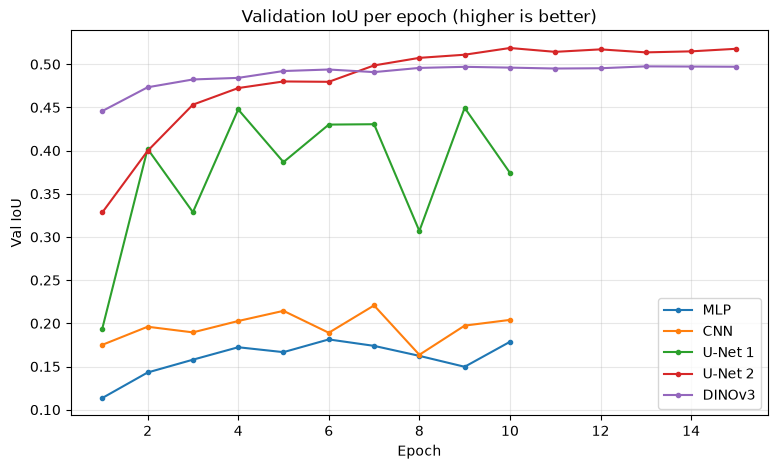

In [17]:
plt.figure(figsize=(9, 5))

for name in seg_models:
    h = histories[name]
    epochs_range = range(1, len(h["val_iou"]) + 1)   # 1, 2, 3, ...
    plt.plot(epochs_range, h["val_iou"], marker="o", markersize=3, label=name)

plt.title("Validation IoU per epoch (higher is better)")
plt.xlabel("Epoch")
plt.ylabel("Val IoU")
plt.grid(alpha=0.3)
plt.legend()

# save before show, otherwise the saved image is empty
plt.savefig(out_dir / "val_iou_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
# best F1 from a crater_scores.json (it holds one result per cutoff)
def best_crater_scores(folder):
    scores = json.loads((folder / "crater_scores.json").read_text())
    cutoff = max(scores, key=lambda c: scores[c]["f1"])
    return scores[cutoff], cutoff

rows = []
for name in ["U-Net 2", "DINOv3"]:
    s, cutoff = best_crater_scores(runs[name])
    rows.append({"Model": name, "Precision": s["precision"], "Recall": s["recall"],
                 "F1": s["f1"], "Cutoff": cutoff})

# Faster R-CNN saved these per epoch in its history, so take its best epoch
h = histories["Faster R-CNN"]
best = h["val_f1"].index(max(h["val_f1"]))
rows.append({"Model": "Faster R-CNN", "Precision": h["val_precision"][best], "Recall": h["val_recall"][best],
             "F1": h["val_f1"][best], "Cutoff": h["best_cutoff"][best]})

table = pd.DataFrame(rows).round(4).rename(columns={"F1": "F1 (higher is better)"})

table.to_csv(out_dir / "crater_scores.csv", index=False)
table.to_latex(out_dir / "crater_scores.tex", index=False)

table.style.highlight_max(subset=["F1 (higher is better)"], color="lightgreen")

,Model,Precision,Recall,F1 (higher is better),Cutoff
0,U-Net 2,0.498000,0.699600,0.581800,0.9
1,DINOv3,0.311200,0.163400,0.214300,0.9
2,Faster R-CNN,0.789500,0.802100,0.795800,0.800000


In [19]:
# how each model started, and how many parameters it actually trained
info = {
    "MLP":          ("from scratch", 525_568),
    "CNN":          ("from scratch", 166_593),
    "U-Net 1":      ("from scratch", 1_925_025),
    "U-Net 2":      ("from scratch", 1_925_025),
    "DINOv3":       ("foundation (frozen)", 385),
    "Faster R-CNN": ("fine-tuned (COCO)", 41_299_161),
}

rows = []
for name, (kind, params) in info.items():
    h = histories[name]

    # pixel IoU: best epoch (Faster R-CNN has none)
    pixel_iou = max(h["val_iou"]) if "val_iou" in h else None

    # crater F1: from crater_scores.json, or Faster R-CNN's history
    if (runs[name] / "crater_scores.json").exists():
        crater_f1 = best_crater_scores(runs[name])[0]["f1"]
    elif "val_f1" in h:
        crater_f1 = max(h["val_f1"])
    else:
        crater_f1 = None   # MLP and CNN were not scored per crater

    rows.append({
        "Model": name,
        "Type": kind,
        "Trained params": f"{params:,}",
        "Epochs": len(h["train_loss"]),
        "Pixel IoU": pixel_iou,
        "Crater F1": crater_f1,
    })

summary = pd.DataFrame(rows).round(4)

summary.to_csv(out_dir / "summary.csv", index=False)
summary.to_latex(out_dir / "summary.tex", index=False, na_rep="-")

summary.style.highlight_max(subset=["Pixel IoU", "Crater F1"], color="lightgreen").format(na_rep="-", precision=4)

,Model,Type,Trained params,Epochs,Pixel IoU,Crater F1
0,MLP,from scratch,"525,568",10,0.1814,-
1,CNN,from scratch,"166,593",10,0.2207,-
2,U-Net 1,from scratch,"1,925,025",10,0.4495,0.4896
3,U-Net 2,from scratch,"1,925,025",15,0.5188,0.5818
4,DINOv3,foundation (frozen),385,15,0.4975,0.2143
5,Faster R-CNN,fine-tuned (COCO),"41,299,161",10,-,0.7958
